# Time-Series Forecasting with SARIMA

**Goal:** Build an end-to-end forecasting pipeline for daily demand: explore the data, decompose it, test stationarity, train and tune a SARIMA model, evaluate it on a held-out test split, and project demand 30 days into the future.

**Data:** Only the provided file `data/daily-demand-series.csv` is used (30 daily observations, 1 June to 30 June 2026). No external data is introduced.

| Column | Meaning |
|---|---|
| `date` | Calendar day |
| `demand` | Daily demand (target variable) |
| `marketing_event` | 1 if a marketing event ran that day |
| `holiday` | 1 if the day was a holiday |

**Pipeline**

1. Load and inspect the data
2. Exploratory analysis
3. Decompose into trend, seasonality and residual
4. Stationarity tests (ADF and KPSS) and differencing
5. Train/test split and SARIMA hyperparameter search
6. Evaluate with MAPE and RMSE on the test split
7. Residual diagnostics
8. Refit on all data and produce a 30-day forecast

## 1. Setup

In [23]:
import os, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")   # small-sample convergence and interpolation warnings
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA_PATH = "../data/daily-demand-series.csv"
FIG_DIR = "../outputs/figures"
OUT_DIR = "../outputs"
os.makedirs(FIG_DIR, exist_ok=True)

SEASON = 7          # weekly seasonality in daily data
TEST_DAYS = 7       # hold out the final week for evaluation
HORIZON = 30        # forecast horizon in days

def save(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

## 2. Load and inspect the data

In [24]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"], index_col="date")
df.index.freq = "D"
print("Shape:", df.shape)
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print("Missing values:\n", df.isna().sum().to_string())
print("Any gaps in daily index:", not (df.index == pd.date_range(df.index.min(), df.index.max(), freq="D")).all())
df.head(10)

Shape: (30, 3)
Date range: 2026-06-01 to 2026-06-30
Missing values:
 demand             0
marketing_event    0
holiday            0
Any gaps in daily index: False


,demand,marketing_event,holiday
date,,,
2026-06-01,118,0,0
2026-06-02,121,0,0
2026-06-03,125,0,0
2026-06-04,123,0,0
2026-06-05,137,1,0
2026-06-06,151,1,0
2026-06-07,143,0,1
2026-06-08,126,0,0
2026-06-09,129,0,0


In [25]:
df.describe().round(2)

,demand,marketing_event,holiday
count,30.00,30.00,30.00
mean,142.10,0.27,0.13
std,13.84,0.45,0.35
min,118.00,0.00,0.00
25%,132.50,0.00,0.00
50%,142.00,0.00,0.00
75%,150.25,0.75,0.00
max,174.00,1.00,1.00


In [26]:
y = df["demand"].astype(float)

## 3. Exploratory analysis

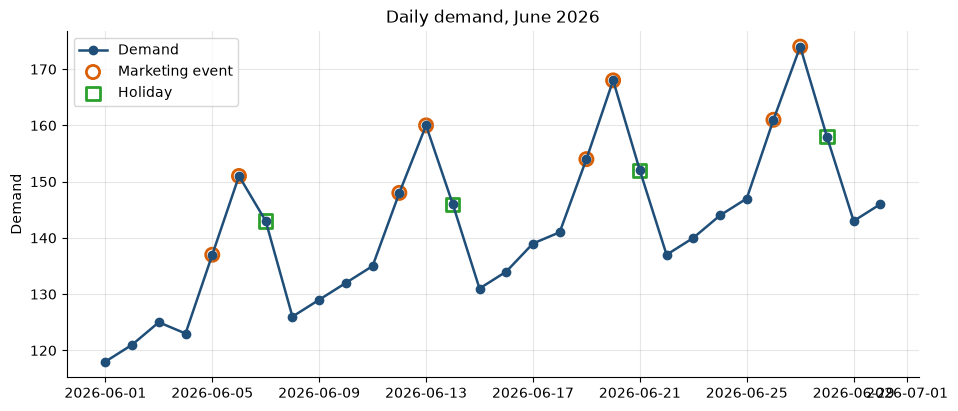

In [27]:
fig, ax = plt.subplots()
ax.plot(y.index, y, marker="o", lw=1.8, label="Demand", color="#1f4e79")
ev = y[df["marketing_event"] == 1]
hol = y[df["holiday"] == 1]
ax.scatter(ev.index, ev, s=90, facecolors="none", edgecolors="#d95f02", lw=2, label="Marketing event")
ax.scatter(hol.index, hol, s=90, marker="s", facecolors="none", edgecolors="#2ca02c", lw=2, label="Holiday")
ax.set_title("Daily demand, June 2026")
ax.set_ylabel("Demand"); ax.legend()
save(fig, "01_demand_overview"); plt.show()

,mean,min,max
day,,,
Monday,131.0,118,143
Tuesday,134.0,121,146
Wednesday,135.0,125,144
Thursday,136.5,123,147
Friday,150.0,137,161
Saturday,163.2,151,174
Sunday,149.8,143,158


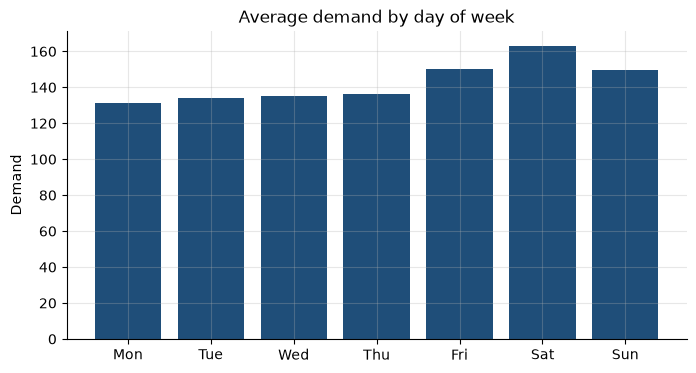

In [28]:
dow = df.assign(day=df.index.day_name()).groupby("day")["demand"].agg(["mean", "min", "max"]).round(1)
dow = dow.reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
display(dow)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dow.index.str[:3], dow["mean"], color="#1f4e79")
ax.set_title("Average demand by day of week"); ax.set_ylabel("Demand")
save(fig, "02_demand_by_weekday"); plt.show()

**Observations**

- Demand climbs steadily across the month, so there is an upward **trend**.
- A clear **weekly cycle** repeats: demand is lowest early in the week and peaks on Friday and Saturday.
- The peaks coincide with the `marketing_event` flag (Friday and Saturday), and the `holiday` flag falls on Sundays. Because these flags repeat every week, their effect is already captured by the weekly seasonality, so the univariate SARIMA model below does not need them as extra inputs.

## 4. Decomposition: trend, seasonality, residual

An additive model is used because the weekly swings stay roughly the same size while the level rises (the seasonal amplitude does not grow in proportion to the level). The period is 7 days.

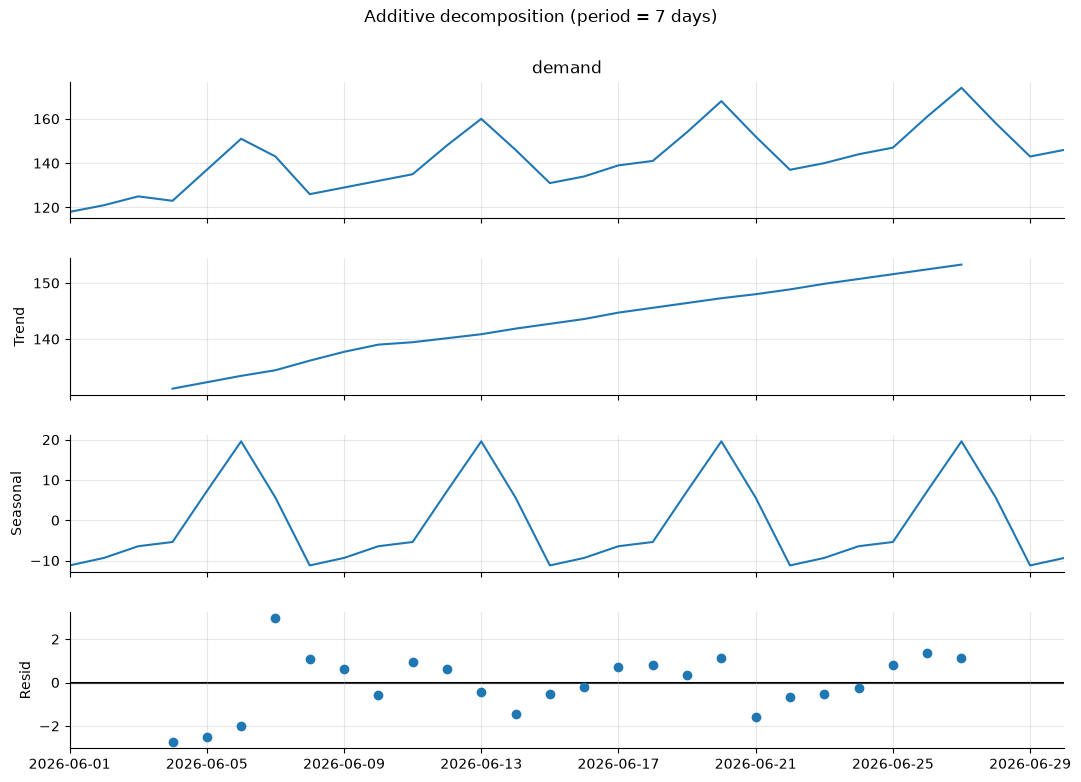

In [29]:
dec = seasonal_decompose(y, model="additive", period=SEASON)
fig = dec.plot()
fig.set_size_inches(11, 8)
fig.suptitle("Additive decomposition (period = 7 days)", y=1.01)
save(fig, "03_decomposition"); plt.show()

In [30]:
resid = dec.resid.dropna()
trend = dec.trend.dropna()
seas = dec.seasonal
Ft = max(0, 1 - resid.var() / (resid + trend.loc[resid.index]).var())
Fs = max(0, 1 - resid.var() / (resid + seas.loc[resid.index]).var())
print(f"Trend strength:       {Ft:.3f}  (1 = fully trend-driven)")
print(f"Seasonality strength: {Fs:.3f}  (1 = fully seasonal)")
print(f"Average weekly trend gain: {(trend.iloc[-1] - trend.iloc[0]) / ((len(trend) - 1) / 7):.2f} units per week")

weekly_pattern = pd.Series(seas.iloc[:7].values, index=seas.index[:7].day_name(), name="seasonal effect").round(2)
weekly_pattern

Trend strength:       0.964  (1 = fully trend-driven)
Seasonality strength: 0.985  (1 = fully seasonal)
Average weekly trend gain: 6.74 units per week


date
Monday      -11.20
Tuesday      -9.35
Wednesday    -6.44
Thursday     -5.39
Friday        7.21
Saturday     19.57
Sunday        5.61
Name: seasonal effect, dtype: float64

**Reading the decomposition**

- **Trend:** a smooth upward line, i.e. demand grows week over week.
- **Seasonality:** a stable weekly profile, with the strongest uplift on Friday and Saturday and the weakest early in the week.
- **Residual:** small and without structure, so trend plus weekly seasonality explains almost all of the variation.

## 5. Stationarity: ADF test and differencing

SARIMA needs a stationary series after differencing. Two complementary tests are used:

- **ADF** (Augmented Dickey-Fuller): the null hypothesis is a unit root (non-stationary). A small p-value suggests stationarity.
- **KPSS**: the null hypothesis is stationarity. A small p-value suggests non-stationarity.

Using both avoids over-trusting one test on such a short series. Only a handful of lags is allowed in the ADF test because there are just 30 observations.

In [31]:
def stationarity_report(s, name, maxlag):
    s = s.dropna()
    adf_stat, adf_p, adf_lags, *_ = adfuller(s, maxlag=maxlag, autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto")
    adf_ok, kpss_ok = adf_p < 0.05, kpss_p > 0.05
    verdict = "Stationary" if adf_ok and kpss_ok else ("Non-stationary" if not adf_ok and not kpss_ok else "Inconclusive")
    return {"Series": name, "n": len(s), "ADF stat": round(adf_stat, 3), "ADF p": round(adf_p, 4),
            "KPSS stat": round(kpss_stat, 3), "KPSS p": round(kpss_p, 3), "Verdict": verdict}

candidates = {
    "Original (d=0, D=0)":              (y, 3),
    "First difference (d=1)":           (y.diff(), 3),
    "Seasonal difference (D=1, lag 7)": (y.diff(SEASON), 1),
    "Both (d=1, D=1)":                  (y.diff(SEASON).diff(), 1),
}
stat_table = pd.DataFrame([stationarity_report(s, n, ml) for n, (s, ml) in candidates.items()]).set_index("Series")
stat_table.to_csv(f"{OUT_DIR}/stationarity_tests.csv")
stat_table

,n,ADF stat,ADF p,KPSS stat,KPSS p,Verdict
Series,,,,,,
"Original (d=0, D=0)",30,-3.287,0.0155,0.653,0.018,Inconclusive
First difference (d=1),29,-7.890,0.0000,0.297,0.100,Stationary
"Seasonal difference (D=1, lag 7)",23,-2.708,0.0726,0.315,0.100,Inconclusive
"Both (d=1, D=1)",22,-5.191,0.0000,0.051,0.100,Stationary


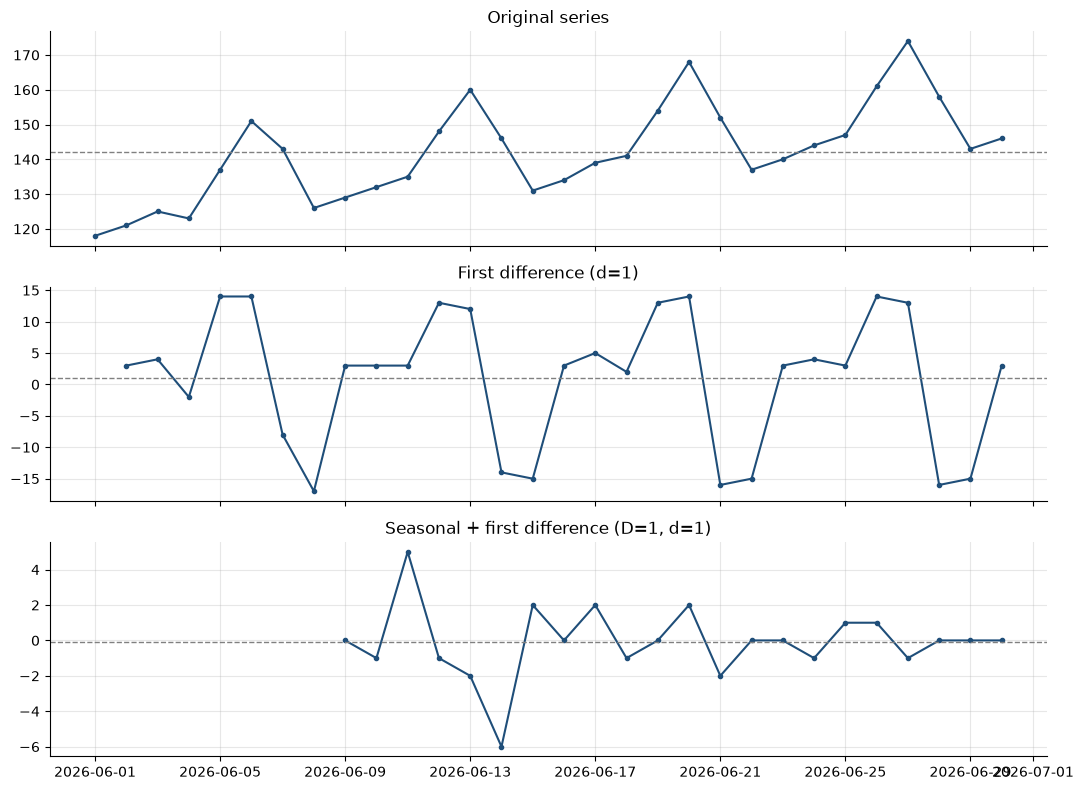

In [32]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
panels = [(y, "Original series"), (y.diff(), "First difference (d=1)"),
          (y.diff(SEASON).diff(), "Seasonal + first difference (D=1, d=1)")]
for ax, (s, t) in zip(axes, panels):
    ax.plot(s.index, s, marker="o", ms=3, color="#1f4e79"); ax.axhline(s.mean(), color="grey", ls="--", lw=1)
    ax.set_title(t)
fig.tight_layout(); save(fig, "04_differencing"); plt.show()

**Decision**

The original series gives conflicting test results and has a plainly visible trend and weekly cycle, so it is treated as non-stationary. A first difference alone passes both tests because it removes the trend, but the weekly cycle is still clearly visible in its plot (and the decomposition shows seasonality is very strong). A seasonal difference at lag 7 removes that cycle. The series differenced both ways passes the ADF test and is not rejected by KPSS, so the model uses **d = 1** and **D = 1** with seasonal period **m = 7**.

### ACF and PACF of the differenced series

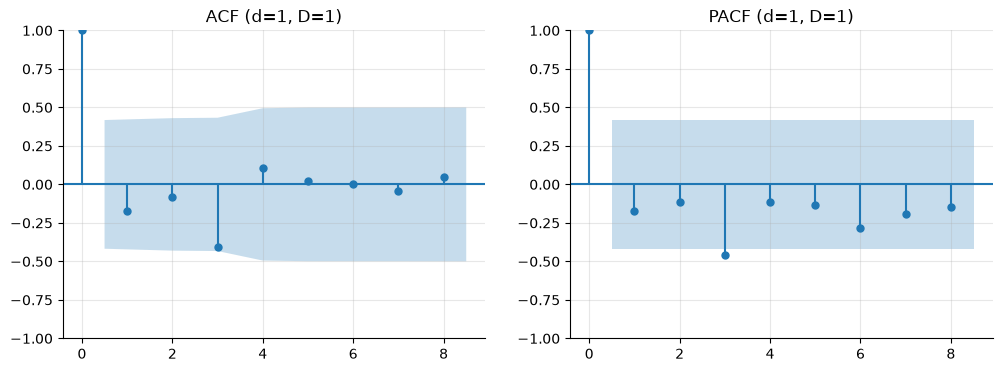

In [33]:
stat = y.diff(SEASON).diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(stat, lags=8, ax=axes[0]); plot_pacf(stat, lags=8, ax=axes[1], method="ywm")
axes[0].set_title("ACF (d=1, D=1)"); axes[1].set_title("PACF (d=1, D=1)")
save(fig, "05_acf_pacf"); plt.show()

With only 22 differenced points these plots are a rough guide, so the final orders are chosen by a small systematic search rather than by eye.

## 6. Train/test split

The last 7 days (one full weekly cycle) are held out as the test set. The model is tuned only on the first 23 days.

In [34]:
train, test = y.iloc[:-TEST_DAYS], y.iloc[-TEST_DAYS:]
print(f"Train: {train.index.min().date()} to {train.index.max().date()}  ({len(train)} days)")
print(f"Test : {test.index.min().date()} to {test.index.max().date()}  ({len(test)} days)")

Train: 2026-06-01 to 2026-06-23  (23 days)
Test : 2026-06-24 to 2026-06-30  (7 days)


## 7. Model training and hyperparameter selection

Metrics used throughout:

- **MAPE** = mean of |actual - forecast| / |actual|, shown as a percentage
- **RMSE** = square root of the mean squared error, in demand units

**Baselines** give context for whether SARIMA is actually adding value:

- *Naive*: repeat the last observed value
- *Seasonal naive*: repeat the value from the same weekday one week earlier

In [35]:
def mape(a, f):  return float(np.mean(np.abs((a - f) / a)) * 100)
def rmse(a, f):  return float(np.sqrt(np.mean((a - f) ** 2)))

naive = pd.Series(train.iloc[-1], index=test.index)
snaive = pd.Series(train.iloc[-SEASON:].values, index=test.index)
baselines = pd.DataFrame({
    "Naive":          {"MAPE (%)": mape(test, naive),  "RMSE": rmse(test, naive)},
    "Seasonal naive": {"MAPE (%)": mape(test, snaive), "RMSE": rmse(test, snaive)},
}).T.round(3)
baselines

,MAPE (%),RMSE
Naive,8.246,17.034
Seasonal naive,3.922,6.024


**Grid search.** Differencing orders are fixed at d = 1 and D = 1 from the stationarity analysis, and the seasonal period at 7. The orders p, q, P, Q are searched over {0, 1}. The grid is kept small on purpose: with 23 training points, 8 of which are consumed by differencing, larger models over-fit. Candidates are ranked by **AIC on the training data only**, so the test split plays no part in selection. Test metrics are shown beside it for transparency.

In [36]:
rows = []
for p, q, P, Q in itertools.product([0, 1], repeat=4):
    try:
        fit = SARIMAX(train, order=(p, 1, q), seasonal_order=(P, 1, Q, SEASON),
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=300)
        fc = fit.forecast(TEST_DAYS)
        rows.append({"order (p,d,q)": f"({p},1,{q})", "seasonal (P,D,Q,m)": f"({P},1,{Q},{SEASON})",
                     "p": p, "q": q, "P": P, "Q": Q,
                     "AIC": fit.aic, "BIC": fit.bic, "Test MAPE (%)": mape(test, fc), "Test RMSE": rmse(test, fc)})
    except Exception as e:
        print("Skipped", (p, q, P, Q), type(e).__name__)

grid = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
grid.drop(columns=["p", "q", "P", "Q"]).round(3).to_csv(f"{OUT_DIR}/hyperparameter_search.csv", index=False)
grid.drop(columns=["p", "q", "P", "Q"]).round(3)

,"order (p,d,q)","seasonal (P,D,Q,m)",AIC,BIC,Test MAPE (%),Test RMSE
0,"(0,1,1)","(0,1,1,7)",21.035,20.410,0.330,0.620
1,"(1,1,1)","(0,1,1,7)",22.332,21.499,0.340,0.646
2,"(0,1,1)","(1,1,1,7)",23.026,22.193,0.647,1.148
3,"(1,1,1)","(1,1,1,7)",24.849,23.808,0.666,1.183
4,"(0,1,0)","(0,1,1,7)",28.191,28.083,0.199,0.539
5,"(1,1,0)","(1,1,0,7)",28.521,28.359,0.191,0.536
6,"(1,1,0)","(0,1,1,7)",28.521,28.359,0.191,0.536
7,"(1,1,1)","(1,1,0,7)",29.226,29.010,0.272,0.573
8,"(0,1,0)","(1,1,1,7)",29.911,29.749,0.584,1.072
9,"(1,1,0)","(1,1,1,7)",30.518,30.302,0.210,0.527


In [37]:
best = grid.iloc[0]
ORDER = (int(best.p), 1, int(best.q))
SORDER = (int(best.P), 1, int(best.Q), SEASON)
print("Selected by lowest training AIC:")
print(f"  SARIMA{ORDER}x{SORDER}   AIC = {best.AIC:.2f}")

Selected by lowest training AIC:
  SARIMA(0, 1, 1)x(0, 1, 1, 7)   AIC = 21.04


## 8. Evaluation on the test split

In [38]:
model = SARIMAX(train, order=ORDER, seasonal_order=SORDER,
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=300)
pred = model.get_forecast(TEST_DAYS)
test_fc = pred.predicted_mean
test_ci = pred.conf_int(alpha=0.05)

results = pd.DataFrame({
    f"SARIMA{ORDER}x{SORDER}": {"MAPE (%)": mape(test, test_fc), "RMSE": rmse(test, test_fc)},
    "Seasonal naive":          {"MAPE (%)": mape(test, snaive),  "RMSE": rmse(test, snaive)},
    "Naive":                   {"MAPE (%)": mape(test, naive),   "RMSE": rmse(test, naive)},
}).T.round(3)
results.to_csv(f"{OUT_DIR}/model_metrics.csv")
results

,MAPE (%),RMSE
"SARIMA(0, 1, 1)x(0, 1, 1, 7)",0.330,0.620
Seasonal naive,3.922,6.024
Naive,8.246,17.034


In [39]:
comparison = pd.DataFrame({"Actual": test, "Forecast": test_fc.round(1),
                           "Lower 95%": test_ci.iloc[:, 0].round(1), "Upper 95%": test_ci.iloc[:, 1].round(1)})
comparison["Abs. error"] = (comparison["Actual"] - comparison["Forecast"]).abs().round(2)
comparison

,Actual,Forecast,Lower 95%,Upper 95%,Abs. error
2026-06-24,144.0,145.3,143.7,147.0,1.3
2026-06-25,147.0,147.3,145.5,149.0,0.3
2026-06-26,161.0,160.3,158.5,162.0,0.7
2026-06-27,174.0,174.4,172.5,176.2,0.4
2026-06-28,158.0,158.3,156.4,160.2,0.3
2026-06-29,143.0,143.3,141.3,145.2,0.3
2026-06-30,146.0,146.3,144.3,148.3,0.3


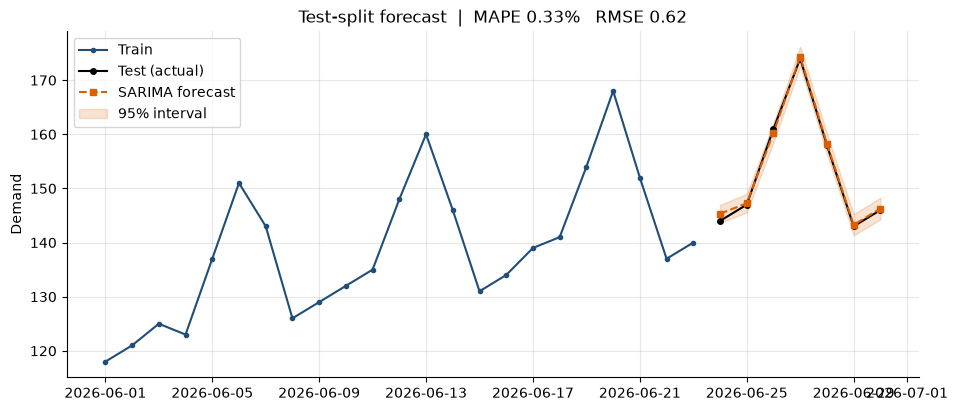

In [40]:
fig, ax = plt.subplots()
ax.plot(train.index, train, color="#1f4e79", marker="o", ms=3, label="Train")
ax.plot(test.index, test, color="black", marker="o", ms=4, label="Test (actual)")
ax.plot(test_fc.index, test_fc, color="#d95f02", marker="s", ms=4, ls="--", label="SARIMA forecast")
ax.fill_between(test.index, test_ci.iloc[:, 0], test_ci.iloc[:, 1], color="#d95f02", alpha=0.18, label="95% interval")
ax.set_title(f"Test-split forecast  |  MAPE {mape(test, test_fc):.2f}%   RMSE {rmse(test, test_fc):.2f}")
ax.set_ylabel("Demand"); ax.legend()
save(fig, "06_test_forecast"); plt.show()

## 9. Residual diagnostics

The first 8 residuals (d + D x m = 1 + 7) belong to the model's initialisation under differencing, so they are excluded.

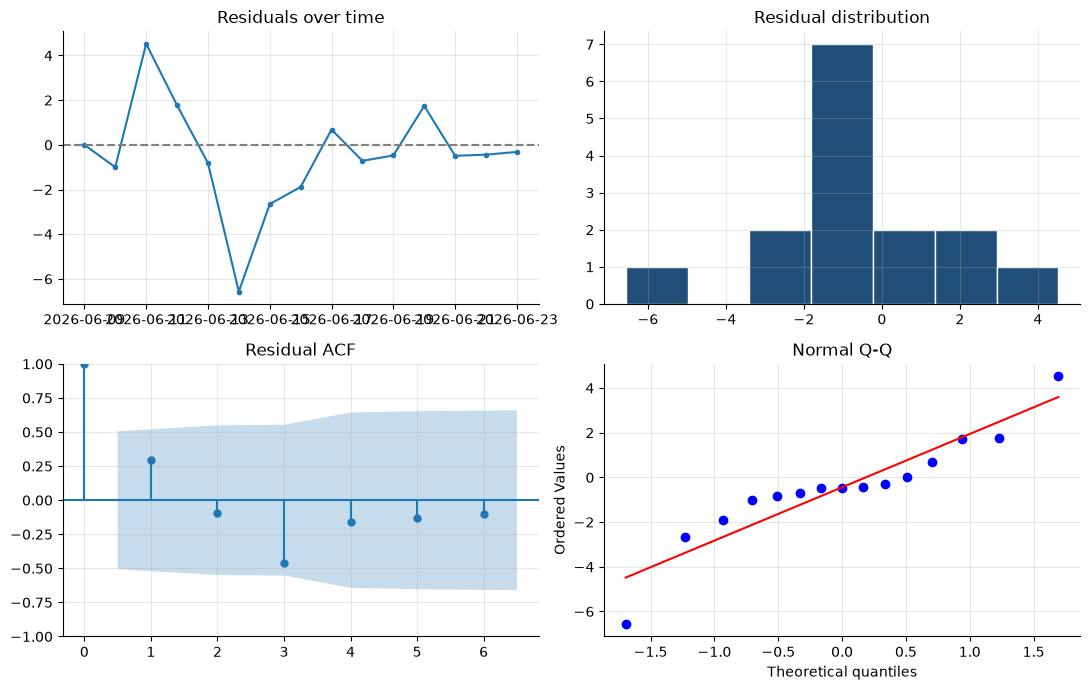

Ljung-Box test (lag 3): p = 0.100  ->  no significant autocorrelation left
Residual mean = -0.442, std = 2.403


In [41]:
res = model.resid.iloc[8:]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].plot(res.index, res, marker="o", ms=3); axes[0, 0].axhline(0, color="grey", ls="--"); axes[0, 0].set_title("Residuals over time")
axes[0, 1].hist(res, bins=7, color="#1f4e79", edgecolor="white"); axes[0, 1].set_title("Residual distribution")
plot_acf(res, lags=6, ax=axes[1, 0]); axes[1, 0].set_title("Residual ACF")
stats.probplot(res, dist="norm", plot=axes[1, 1]); axes[1, 1].set_title("Normal Q-Q")
fig.tight_layout(); save(fig, "07_residual_diagnostics"); plt.show()

lb = acorr_ljungbox(res, lags=[3], return_df=True)
p_lb = lb["lb_pvalue"].iloc[0]
print(f"Ljung-Box test (lag 3): p = {p_lb:.3f}  ->  " + ("no significant autocorrelation left" if p_lb > 0.05 else "some autocorrelation remains"))
print(f"Residual mean = {res.mean():.3f}, std = {res.std():.3f}")

## 10. Final model and 30-day forecast

The selected specification is refit on **all 30 days**, then used to project the next 30 days (1 July to 30 July 2026). Shaded bands are 95% prediction intervals; they widen with the horizon because uncertainty accumulates.

In [42]:
final = SARIMAX(y, order=ORDER, seasonal_order=SORDER,
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=300)
fut = final.get_forecast(HORIZON)
future_index = pd.date_range(y.index[-1] + pd.Timedelta(days=1), periods=HORIZON, freq="D")
ci = fut.conf_int(alpha=0.05)
forecast = pd.DataFrame({
    "date": future_index,
    "weekday": future_index.day_name(),
    "forecast": fut.predicted_mean.values,
    "lower_95": ci.iloc[:, 0].values,
    "upper_95": ci.iloc[:, 1].values,
}).round(2)
forecast.to_csv(f"{OUT_DIR}/forecast_30_day.csv", index=False)
forecast

,date,weekday,forecast,lower_95,upper_95
0,2026-07-01,Wednesday,150.04,148.58,151.51
1,2026-07-02,Thursday,153.06,151.54,154.58
2,2026-07-03,Friday,167.08,165.51,168.65
3,2026-07-04,Saturday,180.06,178.44,181.68
4,2026-07-05,Sunday,164.06,162.39,165.73
5,2026-07-06,Monday,149.06,147.34,150.78
6,2026-07-07,Tuesday,152.06,150.30,153.83
7,2026-07-08,Wednesday,156.11,153.52,158.70
8,2026-07-09,Thursday,159.12,156.41,161.84
9,2026-07-10,Friday,173.14,170.31,175.98


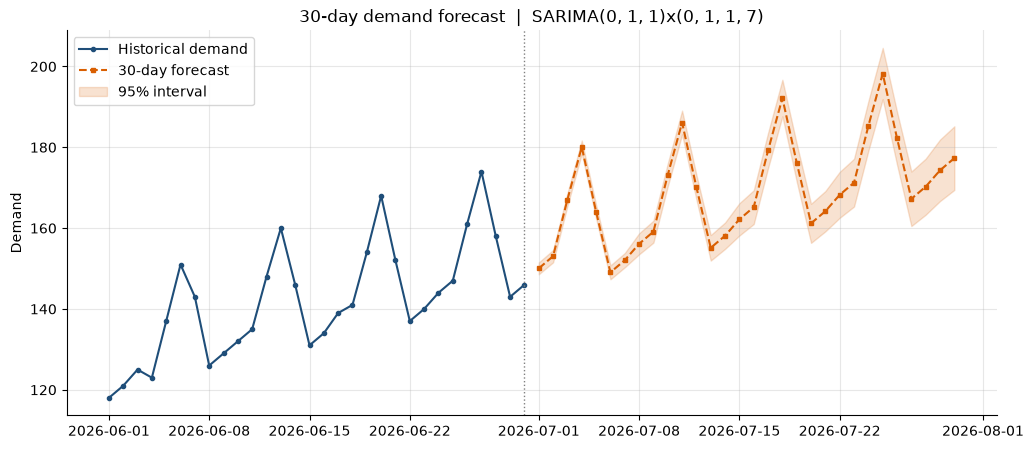

In [43]:
f = forecast.set_index("date")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index, y, color="#1f4e79", marker="o", ms=3, label="Historical demand")
ax.plot(f.index, f["forecast"], color="#d95f02", marker="s", ms=3, ls="--", label="30-day forecast")
ax.fill_between(f.index, f["lower_95"], f["upper_95"], color="#d95f02", alpha=0.18, label="95% interval")
ax.axvline(y.index[-1], color="grey", ls=":", lw=1)
ax.set_title(f"30-day demand forecast  |  SARIMA{ORDER}x{SORDER}")
ax.set_ylabel("Demand"); ax.legend()
save(fig, "08_forecast_30_day"); plt.show()

In [44]:
full = forecast.iloc[:28].assign(week=np.repeat(np.arange(1, 5), 7))
weekly = full.groupby("week")["forecast"].mean().round(1)
print("Average forecast demand per full week of the horizon (days 1-28):")
print(weekly.to_string())
print(f"\nLast observed week average (24-30 Jun): {y.iloc[-7:].mean():.1f}")

Average forecast demand per full week of the horizon (days 1-28):
week
1    159.3
2    165.4
3    171.5
4    177.5

Last observed week average (24-30 Jun): 153.3


## 11. Conclusions and limitations

**Findings**

- Demand has a clear upward trend and a strong, stable weekly cycle (peaks on Friday and Saturday).
- The series needs one regular and one seasonal difference (d = 1, D = 1, m = 7) to become stationary.
- The tuned SARIMA model beats the naive and seasonal-naive baselines on the held-out week (see the metrics table above).
- Residuals show no meaningful leftover autocorrelation.

**Limitations to keep in mind**

- The dataset has only **30 daily observations (about 4 weekly cycles)**. The error on the test week is small, but a single test week on so little history is weak evidence, and the long-horizon forecast depends on the pattern and trend of June continuing unchanged.
- The 95% intervals are narrow because the June data is very regular. Real demand can change in ways one month of history cannot reveal, so treat the intervals as optimistic.
- The 30-day forecast extends the June trend. Anything outside the data (promotions, supply limits, calendar effects beyond June) is not represented.
- `marketing_event` and `holiday` were not used as model inputs because they repeat weekly and are already absorbed by the seasonal terms. Using them as regressors would require assuming their future values, which are not in the data.
- Prophet was not used: it needs several seasonal cycles of history (ideally a year or more) to fit well, and SARIMA is the better fit for 30 points.